# مقایسهٔ Transformerها برای نظرهای فارسی دیجی‌کالا

این نوت‌بوک سه مدل ازپیش‌آموزش‌دیده را از نظر tokenizer، طول ورودی و توانایی یادگیری دو دسته‌بند پروژه مقایسه می‌کند: ParsBERT، XLM-RoBERTa و multilingual BERT. بررسی tokenizer به تصمیم‌گیری دربارهٔ max_length کمک می‌کند؛ مقایسهٔ واقعی مدل‌ها با fine-tuning روی برچسب‌های پروژه انجام می‌شود.

این نوت‌بوک برای انتخاب اولیه است و جای ارزیابی نهایی پروژه را نمی‌گیرد. ورودی مدل فقط متن body است.

## ۱. تنظیمات و مسیر داده

این سلول مسیر splitهای آماده و شناسهٔ مدل‌ها را مشخص می‌کند. طول متن‌ها از train محاسبه می‌شود. validation برای نمایش چند نمونه و سنجش مدل به کار می‌رود، نه برای محاسبهٔ آماری طول ورودی.

In [1]:
from pathlib import Path
import json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "clean_data" / "split_body_cleaned"
TRAIN_PATH = DATA_DIR / "train_supervised.csv"
VALID_PATH = DATA_DIR / "validation.csv"
MANIFEST_PATH = DATA_DIR / "split_manifest.json"
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f"Split files not found: {DATA_DIR}. Run preprocessing first.")
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

MODELS = {
    "ParsBERT": "HooshvareLab/bert-fa-base-uncased",
    "XLM-RoBERTa": "FacebookAI/xlm-roberta-base",
    "mBERT": "google-bert/bert-base-multilingual-cased",
}
TARGETS = {
    "recommendation_status": ["recommended", "not_recommended", "no_idea"],
    "rating_band": ["low", "medium", "high"],
}
# زیرنمونهٔ تصادفی و ثابت برای مقایسهٔ منصفانهٔ مدل‌ها.
RUN_FINETUNING = True
FINETUNE_LIMIT = 3_000
EPOCHS = 1
BATCH_SIZE = 8
print("پروژه:", ROOT)
print("مسیر داده:", DATA_DIR)
print("مدل‌ها:", list(MODELS))

پروژه: E:\MLprojects\Transformer-Project
مسیر داده: E:\MLprojects\Transformer-Project\data\clean_data\split_body_cleaned
مدل‌ها: ['ParsBERT', 'XLM-RoBERTa', 'mBERT']


## ۲. وابستگی‌ها

Tokenizerها و مدل‌ها با Transformers بارگذاری می‌شوند. دریافت checkpoint از Hugging Face به اینترنت نیاز دارد. اگر import ناموفق بود، در محیط پروژه transformers را نصب و kernel را راه‌اندازی مجدد کن.

In [2]:
try:
    import torch
    from transformers import AutoTokenizer, AutoModel
except ImportError as exc:
    raise ImportError("برای اجرای این نوت‌بوک، transformers و torch را نصب کن: pip install transformers torch") from exc

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| دستگاه:", DEVICE)

E:\MLprojects\Transformer-Project\.project_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.1+cpu | دستگاه: cpu


## ۳. متن‌های کنترل‌شده

این مثال‌ها فارسی معیار، محاوره‌ای، فینگلیش، متن ترکیبی و متن‌های خارج از فضای نظر محصول را پوشش می‌دهند. هدف مشاهدهٔ نحوهٔ خردشدن متن است؛ چند مثال به‌تنهایی نمایندهٔ کل زبان نیستند.

In [3]:
manual_texts = {
    "فارسی معیار": "کیفیت ساخت محصول خوب است و استفاده از آن آسان است.",
    "محاوره‌ای": "خیلی خوبه، فقط بسته‌بندیش یه کم ضعیف بود.",
    "فینگلیش": "kheili khube vali baste bandish zaeife",
    "ترکیبی": "این گوشی واقعا fast هست ولی باتریش زود تموم میشه.",
    "خارج از دیجی‌کالا": "امروز باران می‌بارید و گربه کنار پنجره خوابش برد.",
    "بلند": " ".join(["کیفیت و تجربهٔ استفاده از این محصول قابل قبول بود"] * 12),
}

## ۴. نمونه‌های واقعی از train و validation

چند نظر واقعی برای بررسی چشمی خوانده می‌شوند. متن‌های validation فقط نمونهٔ نمایشی و ارزیابی‌اند. محاسبات آماری max_length در بخش بعد از تمام متن‌های train انجام می‌شود.

In [4]:
def read_preview(path, n=10):
    columns = ["body", *TARGETS]
    frame = pd.read_csv(path, usecols=lambda name: name in columns, nrows=n)
    frame["body"] = frame["body"].fillna("").astype(str)
    return frame

train_preview = read_preview(TRAIN_PATH)
valid_preview = read_preview(VALID_PATH)
print("Train preview")
display(train_preview.head())
print("Validation preview")
display(valid_preview.head())


Train preview


,body,recommendation_status,rating_band
0,به درد نمیخوره,not_recommended,low
1,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,recommended,low
2,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,recommended,low
3,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,recommended,medium
4,قبلا هم استفاده کردم اگه بلد باشین کار کردن با...,recommended,high


Validation preview


,body,recommendation_status,rating_band
0,بسته بندیش خوب بود کاربرد و کیفیتشم خیلی خوبه ...,recommended,low
1,خوبه,NaN,low
2,خیلی به کارتون میاد قیمتشم مناسبه,recommended,high
3,اندازش کوچیکه بدرد رنگ مو نمیخوره,not_recommended,low
4,خوب بود بخرید قشنگه,recommended,high


<div dir="rtl">

## ۵. بارگذاری tokenizerها و بررسی نمونه‌ها

برای هر متن، تعداد token و قطعه‌های سازندهٔ آن نمایش داده می‌شود. در این مرحله کوتاه‌سازی انجام نمی‌شود تا طول طبیعی متن دیده شود.

In [7]:
tokenizers = {}
for name, checkpoint in MODELS.items():
    try:
        tokenizers[name] = AutoTokenizer.from_pretrained(checkpoint)
        print("بارگذاری شد:", name)
    except Exception as exc:
        warnings.warn(f"بارگذاری {checkpoint} ناموفق بود: {exc}")
if not tokenizers:
    raise RuntimeError("هیچ tokenizer بارگذاری نشد؛ اینترنت و شناسهٔ مدل‌ها را بررسی کن.")

rows = []
for sample_name, text in manual_texts.items():
    for name, tokenizer in tokenizers.items():
        pieces = tokenizer.tokenize(text)
        rows.append({
            "نمونه": sample_name,
            "مدل": name,
            "متن اصلی": text,
            "تعداد token": len(pieces),
            "قطعه‌ها": " | ".join(pieces),
        })

tokenizer_report = pd.DataFrame(rows)
report_dir = ROOT / "reports"
report_dir.mkdir(parents=True, exist_ok=True)
report_path = report_dir / "tokenizer_manual_examples.csv"
tokenizer_report.to_csv(report_path, index=False, encoding="utf-8-sig")
print(f"گزارش کامل ذخیره شد: {report_path}")

# نمایش را بدون کوتاه‌کردن متن ستون قطعه‌ها انجام می‌دهیم.
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(tokenizer_report)


بارگذاری شد: ParsBERT
بارگذاری شد: XLM-RoBERTa
بارگذاری شد: mBERT
گزارش کامل ذخیره شد: E:\MLprojects\Transformer-Project\reports\tokenizer_manual_examples.csv


,نمونه,مدل,متن اصلی,تعداد token,قطعه‌ها
0,فارسی معیار,ParsBERT,کیفیت ساخت محصول خوب است و استفاده از آن آسان است.,12,کیفیت | ساخت | محصول | خوب | است | و | استفاده | از | ان | اسان | است | .
1,فارسی معیار,XLM-RoBERTa,کیفیت ساخت محصول خوب است و استفاده از آن آسان است.,12,▁کیفیت | ▁ساخت | ▁محصول | ▁خوب | ▁است | ▁و | ▁استفاده | ▁از | ▁آن | ▁آسان | ▁است | .
2,فارسی معیار,mBERT,کیفیت ساخت محصول خوب است و استفاده از آن آسان است.,15,کی | ##فی | ##ت | ساخت | محصول | خوب | است | و | استفاده | از | آن | آ | ##سان | است | .
3,محاوره‌ای,ParsBERT,خیلی خوبه، فقط بسته‌بندیش یه کم ضعیف بود.,11,خیلی | خوبه | ، | فقط | بستهبندی | ##ش | یه | کم | ضعیف | بود | .
4,محاوره‌ای,XLM-RoBERTa,خیلی خوبه، فقط بسته‌بندیش یه کم ضعیف بود.,13,▁خیلی | ▁خوب | ه | ، | ▁فقط | ▁بسته | ▁بندی | ش | ▁یه | ▁کم | ▁ضعیف | ▁بود | .
5,محاوره‌ای,mBERT,خیلی خوبه، فقط بسته‌بندیش یه کم ضعیف بود.,17,خ | ##یلی | خوب | ##ه | ، | فقط | بسته | ##بندی | ##ش | ی | ##ه | کم | ض | ##عی | ##ف | بود | .
6,فینگلیش,ParsBERT,kheili khube vali baste bandish zaeife,14,kh | ##ei | ##li | kh | ##ube | val | ##i | bast | ##e | band | ##ish | za | ##ei | ##fe
7,فینگلیش,XLM-RoBERTa,kheili khube vali baste bandish zaeife,12,▁khe | ili | ▁khu | be | ▁vali | ▁bas | te | ▁band | ish | ▁za | e | ife
8,فینگلیش,mBERT,kheili khube vali baste bandish zaeife,14,k | ##hei | ##li | khu | ##be | val | ##i | bas | ##te | band | ##ish | za | ##ei | ##fe
9,ترکیبی,ParsBERT,این گوشی واقعا fast هست ولی باتریش زود تموم میشه.,12,این | گوشی | واقعا | fast | هست | ولی | باتری | ##ش | زود | تموم | میشه | .


## ۶. Tokenizer روی نظرهای واقعی

این جدول چند متن واقعی را کنار هم می‌گذارد تا تفاوت tokenizerها در متن طبیعی دیده شود. فقط ابتدای فهرست tokenها نمایش داده می‌شود تا جدول خوانا بماند.

In [6]:
real = pd.concat([train_preview.assign(split="train"), valid_preview.assign(split="validation")], ignore_index=True).head(8)
rows = []
for _, row in real.iterrows():
    for name, tokenizer in tokenizers.items():
        pieces = tokenizer.tokenize(row["body"])
        rows.append({"بخش": row["split"], "مدل": name, "متن": row["body"][:160],
                     "تعداد token": len(pieces), "ابتدای قطعه‌ها": " | ".join(pieces[:35])})
display(pd.DataFrame(rows))

,بخش,مدل,متن,تعداد token,ابتدای قطعه‌ها
0,train,ParsBERT,به درد نمیخوره,4,به | درد | نمیخو | ##ره
1,train,XLM-RoBERTa,به درد نمیخوره,5,▁به | ▁درد | ▁نمی | خور | ه
2,train,mBERT,به درد نمیخوره,7,به | درد | ن | ##می | ##خ | ##ور | ##ه
3,train,ParsBERT,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,10,میتونست | به | عنوان | یه | کالای | فرهنگی | ب...
4,train,XLM-RoBERTa,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,12,▁می | ▁تونس | ت | ▁به | ▁عنوان | ▁یه | ▁کالای ...
5,train,mBERT,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,19,می | ##تون | ##ست | به | عنوان | ی | ##ه | کا ...
6,train,ParsBERT,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,20,به | نظرم | خوبه | فقط | یکم | ظریف | ##ه | . ...
7,train,XLM-RoBERTa,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,28,▁به | ▁نظر | م | ▁خوب | ه | ▁فقط | ▁یک | م | ▁...
8,train,mBERT,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,34,به | نظر | ##م | خوب | ##ه | فقط | یک | ##م | ...
9,train,ParsBERT,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,22,معمولی | ##ه | اگه | واسه | خونه | رنگ | کردن ...


## ۷. طول تمام متن‌های train

فایل train چندمیلیونی است؛ بنابراین متن‌ها به‌صورت batch خوانده می‌شوند و هم‌زمان در حافظه بارگذاری نمی‌شوند. این محاسبه ممکن است زمان ببرد و برای هر سه مدل جداگانه انجام می‌شود. شمارش شامل tokenهای ویژهٔ مدل نیز هست.

In [7]:
def token_lengths(csv_path, tokenizer, batch_size=256):
    lengths = []
    processed = 0
    for chunk in pd.read_csv(csv_path, usecols=["body"], chunksize=batch_size):
        texts = chunk["body"].fillna("").astype(str).tolist()
        encoded = tokenizer(texts, add_special_tokens=True, truncation=False, padding=False)
        lengths.extend(len(ids) for ids in encoded["input_ids"])
        processed += len(texts)
        if processed % 100_000 < batch_size:
            print(f"پردازش شد: {processed:,}")
    return np.asarray(lengths, dtype=np.int32)

LENGTHS = {}
for name, tokenizer in tokenizers.items():
    print("محاسبه برای", name)
    LENGTHS[name] = token_lengths(TRAIN_PATH, tokenizer)

محاسبه برای ParsBERT
پردازش شد: 100,096
پردازش شد: 200,192
پردازش شد: 300,032
پردازش شد: 400,128
پردازش شد: 500,224
پردازش شد: 600,064
پردازش شد: 700,160
پردازش شد: 800,000
پردازش شد: 900,096
پردازش شد: 1,000,192
پردازش شد: 1,100,032
پردازش شد: 1,200,128
پردازش شد: 1,300,224
پردازش شد: 1,400,064
پردازش شد: 1,500,160
پردازش شد: 1,600,000
پردازش شد: 1,700,096
پردازش شد: 1,800,192
پردازش شد: 1,900,032
پردازش شد: 2,000,128
پردازش شد: 2,100,224
پردازش شد: 2,200,064
پردازش شد: 2,300,160
پردازش شد: 2,400,000
پردازش شد: 2,500,096
پردازش شد: 2,600,192
پردازش شد: 2,700,032
پردازش شد: 2,800,128
پردازش شد: 2,900,224
پردازش شد: 3,000,064
پردازش شد: 3,100,160
پردازش شد: 3,200,000
پردازش شد: 3,300,096
پردازش شد: 3,400,192
پردازش شد: 3,500,032


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (581 > 512). Running this sequence through the model will result in indexing errors


محاسبه برای XLM-RoBERTa
پردازش شد: 100,096
پردازش شد: 200,192
پردازش شد: 300,032
پردازش شد: 400,128
پردازش شد: 500,224
پردازش شد: 600,064
پردازش شد: 700,160
پردازش شد: 800,000
پردازش شد: 900,096
پردازش شد: 1,000,192
پردازش شد: 1,100,032
پردازش شد: 1,200,128
پردازش شد: 1,300,224
پردازش شد: 1,400,064
پردازش شد: 1,500,160
پردازش شد: 1,600,000
پردازش شد: 1,700,096
پردازش شد: 1,800,192
پردازش شد: 1,900,032
پردازش شد: 2,000,128
پردازش شد: 2,100,224
پردازش شد: 2,200,064
پردازش شد: 2,300,160
پردازش شد: 2,400,000
پردازش شد: 2,500,096
پردازش شد: 2,600,192
پردازش شد: 2,700,032
پردازش شد: 2,800,128
پردازش شد: 2,900,224
پردازش شد: 3,000,064
پردازش شد: 3,100,160
پردازش شد: 3,200,000
پردازش شد: 3,300,096
پردازش شد: 3,400,192
پردازش شد: 3,500,032


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (734 > 512). Running this sequence through the model will result in indexing errors


محاسبه برای mBERT
پردازش شد: 100,096
پردازش شد: 200,192
پردازش شد: 300,032
پردازش شد: 400,128
پردازش شد: 500,224
پردازش شد: 600,064
پردازش شد: 700,160
پردازش شد: 800,000
پردازش شد: 900,096
پردازش شد: 1,000,192
پردازش شد: 1,100,032
پردازش شد: 1,200,128
پردازش شد: 1,300,224
پردازش شد: 1,400,064
پردازش شد: 1,500,160
پردازش شد: 1,600,000
پردازش شد: 1,700,096
پردازش شد: 1,800,192
پردازش شد: 1,900,032
پردازش شد: 2,000,128
پردازش شد: 2,100,224
پردازش شد: 2,200,064
پردازش شد: 2,300,160
پردازش شد: 2,400,000
پردازش شد: 2,500,096
پردازش شد: 2,600,192
پردازش شد: 2,700,032
پردازش شد: 2,800,128
پردازش شد: 2,900,224
پردازش شد: 3,000,064
پردازش شد: 3,100,160
پردازش شد: 3,200,000
پردازش شد: 3,300,096
پردازش شد: 3,400,192
پردازش شد: 3,500,032


## ۸. خلاصهٔ آماری و نمودار طول

جدول میانگین، میانه، صدک‌ها و بیشینه را نشان می‌دهد. نمودارها برای خوانایی تا صدک ۹۹ رسم می‌شوند؛ جدول همچنان بیشینهٔ واقعی را دارد.

,تعداد متن,میانگین,میانه,صدک ۷۵,صدک ۹۰,صدک ۹۵,صدک ۹۸,صدک ۹۹,بیشینه
ParsBERT,3572367.0,13.6,9.0,16.0,28.0,39.0,57.0,73.0,989.0
XLM-RoBERTa,3572367.0,16.2,10.0,19.0,33.0,47.0,69.0,89.0,1278.0
mBERT,3572367.0,20.8,13.0,24.0,43.0,61.0,90.0,116.0,1585.0


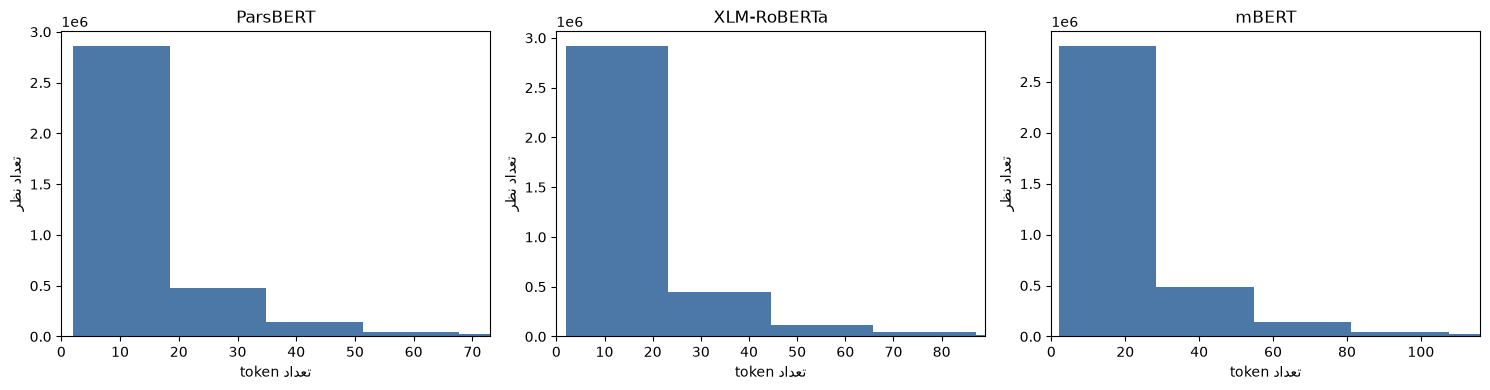

In [8]:
def summarize(values):
    q = np.percentile(values, [50, 75, 90, 95, 98, 99])
    return {"تعداد متن": len(values), "میانگین": values.mean(), "میانه": q[0], "صدک ۷۵": q[1],
            "صدک ۹۰": q[2], "صدک ۹۵": q[3], "صدک ۹۸": q[4], "صدک ۹۹": q[5], "بیشینه": values.max()}

summary = pd.DataFrame({name: summarize(values) for name, values in LENGTHS.items()}).T
display(summary.round(1))
fig, axes = plt.subplots(1, len(LENGTHS), figsize=(5 * len(LENGTHS), 4), squeeze=False)
for ax, (name, values) in zip(axes[0], LENGTHS.items()):
    ax.hist(values, bins=60, color="#4C78A8")
    ax.set_xlim(0, np.percentile(values, 99))
    ax.set_title(name)
    ax.set_xlabel("تعداد token")
    ax.set_ylabel("تعداد نظر")
plt.tight_layout()
plt.show()

## ۹. بررسی گزینه‌های max_length

برای چند طول نامزد، درصد متن‌های train که کامل جا می‌شوند و درصدی که کوتاه خواهند شد محاسبه می‌شود. انتخاب باید میان پوشش نظرها و هزینهٔ اجرا تعادل برقرار کند. سقف هر tokenizer رعایت می‌شود.

,مدل,حداکثر طول,کامل جا می‌شود (درصد),کوتاه می‌شود (درصد),میانگین token پردازش‌شده
0,ParsBERT,128,99.81,0.19,13.54
1,ParsBERT,256,99.98,0.02,13.63
2,ParsBERT,384,99.99,0.01,13.64
3,ParsBERT,512,100.00,0.00,13.65
4,XLM-RoBERTa,128,99.65,0.35,15.98
5,XLM-RoBERTa,256,99.96,0.04,16.15
6,XLM-RoBERTa,384,99.99,0.01,16.18
7,XLM-RoBERTa,512,100.00,0.00,16.19
8,mBERT,128,99.25,0.75,20.30
9,mBERT,256,99.91,0.09,20.67


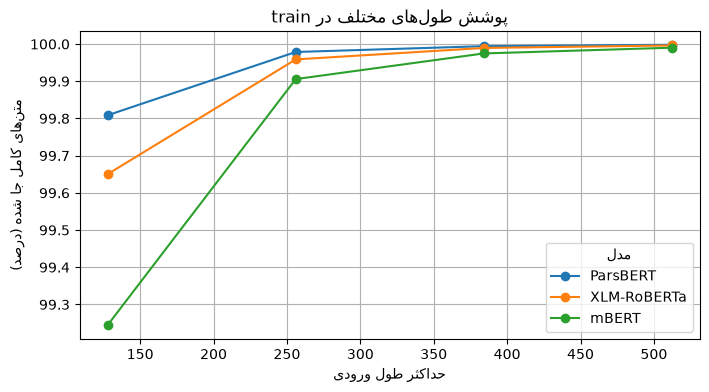

In [9]:
rows = []
for name, tokenizer in tokenizers.items():
    limit = getattr(tokenizer, "model_max_length", 512)
    if limit is None or limit > 100_000:
        limit = 512
    for candidate in [128, 256, 384, 512]:
        if candidate <= limit:
            values = LENGTHS[name]
            rows.append({"مدل": name, "حداکثر طول": candidate,
                         "کامل جا می‌شود (درصد)": 100 * np.mean(values <= candidate),
                         "کوتاه می‌شود (درصد)": 100 * np.mean(values > candidate),
                         "میانگین token پردازش‌شده": np.minimum(values, candidate).mean()})
max_length_table = pd.DataFrame(rows)
display(max_length_table.round(2))
ax = max_length_table.pivot(index="حداکثر طول", columns="مدل", values="کامل جا می‌شود (درصد)").plot(marker="o", grid=True, figsize=(8, 4))
ax.set_ylabel("متن‌های کامل جا شده (درصد)")
ax.set_xlabel("حداکثر طول ورودی")
ax.set_title("پوشش طول‌های مختلف در train")
plt.show()

## ۱۰. Fine-tuning روی زیرنمونهٔ تصادفی ۱۰۰هزارتایی

هر سه مدل با یک زیرنمونهٔ تصادفیِ یکسان از train_supervised آموزش می‌بینند. دو سرِ طبقه‌بندی برای recommendation_status و rating_band از ابتدا ساخته و همراه encoder آموزش داده می‌شوند. اگر یک ردیف یکی از برچسب‌ها را نداشته باشد، فقط loss همان سر نادیده گرفته می‌شود.

انتخاب ۱۰۰هزار ردیف به‌صورت قطعه‌ای و با seed ثابت انجام می‌شود؛ پس کل فایل در حافظه بارگذاری نمی‌شود و هر سه مدل دقیقاً همان ردیف‌ها را می‌بینند. آموزش یک epoch است، طول ورودی پیش‌فرض ۱۲۸ و padding در هر batch پویاست. روی CPU هنوز ممکن است زمان زیادی ببرد؛ نوت‌بوک هر ۱۰۰۰ batch زمان سپری‌شده و برآورد تقریبی باقی‌مانده را چاپ می‌کند.

In [10]:
# مقدار ۱۲۸ برای اجرای CPU سبک‌تر است؛ padding هر batch پویاست.
MAX_LENGTH_BY_MODEL = {name: min(128, int(getattr(tok, "model_max_length", 512))) for name, tok in tokenizers.items()}
print("حداکثر طول آموزش:", MAX_LENGTH_BY_MODEL)
print(f"تعداد نمونهٔ آموزش برای هر مدل: {FINETUNE_LIMIT:,}")
print("Fine-tuning فعال است؛ هر سه مدل از یک نمونهٔ تصادفی مشترک استفاده می‌کنند.")

حداکثر طول آموزش: {'ParsBERT': 128, 'XLM-RoBERTa': 128, 'mBERT': 128}
تعداد نمونهٔ آموزش برای هر مدل: 3,000
Fine-tuning فعال است؛ هر سه مدل از یک نمونهٔ تصادفی مشترک استفاده می‌کنند.


## ۱۱. نمونه‌گیری، آموزش و ارزیابی

ابتدا ۱۰۰هزار ردیف با انتخاب تصادفیِ قابل‌بازتولید از train جدا و در فایل موقت ذخیره می‌شوند. سپس هر سه مدل روی همان نمونه آموزش می‌بینند. دادهٔ validation برای ارزیابی از یک نمونهٔ تصادفی ثابت ۱۵۰۰تایی استفاده می‌کند. معیارهای Accuracy و Macro F1 برای هر دو هدف گزارش می‌شوند. برآورد زمان حین آموزش تقریبی است و با سرعت batchهای واقعی CPU به‌روز می‌شود.

In [11]:
if RUN_FINETUNING:
    import time
    import tempfile
    import torch
    from torch import nn
    from torch.utils.data import Dataset, IterableDataset, DataLoader
    from sklearn.metrics import accuracy_score, f1_score

    def create_random_train_sample(path, sample_size, seed):
        """Create an exact, reproducible row sample without loading the full CSV."""
        total = int(manifest["output_row_counts"]["train_supervised"])
        take = min(sample_size, total)
        rng = np.random.default_rng(seed)
        selected = np.sort(rng.choice(total, size=take, replace=False))
        sample_path = Path(tempfile.gettempdir()) / f"digikala_train_sample_{take}_seed{seed}.csv"
        offset = 0
        first_write = True
        for chunk in pd.read_csv(
            path, usecols=lambda col: col in {"body", *TARGETS}, chunksize=50_000
        ):
            left = np.searchsorted(selected, offset, side="left")
            right = np.searchsorted(selected, offset + len(chunk), side="left")
            if right > left:
                local_indices = selected[left:right] - offset
                chosen = chunk.iloc[local_indices].copy()
                chosen["body"] = chosen["body"].fillna("")
                chosen.to_csv(sample_path, mode="w" if first_write else "a",
                              header=first_write, index=False, encoding="utf-8")
                first_write = False
            offset += len(chunk)
        if first_write:
            raise RuntimeError("نمونهٔ train ساخته نشد؛ تعداد ردیف‌های manifest را بررسی کن.")
        print(f"نمونهٔ ثابت ساخته شد: {take:,} ردیف")
        return sample_path

    class StreamingReviews(IterableDataset):
        """Read the saved sample in chunks and shuffle each chunk reproducibly."""
        def __init__(self, path):
            self.path = path
        def __iter__(self):
            reader = pd.read_csv(
                self.path, usecols=lambda col: col in {"body", *TARGETS}, chunksize=10_000
            )
            for chunk_number, chunk in enumerate(reader):
                chunk = chunk.sample(frac=1, random_state=SEED + chunk_number)
                for row in chunk.to_dict("records"):
                    yield row

    def sample_validation(path, sample_size=1500):
        """Take a reproducible approximate-uniform sample across CSV chunks."""
        total = int(manifest["output_row_counts"]["validation"])
        fraction = min(1.0, sample_size / total * 1.15)
        samples = []
        for chunk_number, chunk in enumerate(pd.read_csv(
            path, usecols=lambda col: col in {"body", *TARGETS}, chunksize=50_000
        )):
            take = chunk.sample(frac=fraction, random_state=SEED + 10_000 + chunk_number)
            samples.append(take)
        result = pd.concat(samples, ignore_index=True)
        if len(result) > sample_size:
            result = result.sample(n=sample_size, random_state=SEED).reset_index(drop=True)
        return result.fillna({"body": ""})

    class ReviewDataset(Dataset):
        def __init__(self, frame):
            self.frame = frame.reset_index(drop=True)
        def __len__(self):
            return len(self.frame)
        def __getitem__(self, index):
            return self.frame.iloc[index].to_dict()

    def make_collator(tokenizer, max_length):
        def collate(rows):
            texts = [str(row.get("body", "")) for row in rows]
            # padding=True means pad only to the longest review in this batch.
            batch = tokenizer(texts, truncation=True, max_length=max_length,
                              padding=True, return_tensors="pt")
            for target, classes in TARGETS.items():
                mapping = {label: index for index, label in enumerate(classes)}
                batch[target] = torch.tensor([
                    mapping.get(row.get(target), -100) for row in rows
                ], dtype=torch.long)
            return batch
        return collate

    class TwoHeadClassifier(nn.Module):
        def __init__(self, checkpoint):
            super().__init__()
            self.encoder = AutoModel.from_pretrained(checkpoint)
            hidden_size = self.encoder.config.hidden_size
            self.heads = nn.ModuleDict({
                target: nn.Linear(hidden_size, len(classes))
                for target, classes in TARGETS.items()
            })
        def forward(self, input_ids, attention_mask):
            output = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
            pooled = output.last_hidden_state[:, 0]
            return {target: head(pooled) for target, head in self.heads.items()}

    train_sample_path = create_random_train_sample(TRAIN_PATH, FINETUNE_LIMIT, SEED)
    validation_frame = sample_validation(VALID_PATH)
    print(f"نمونهٔ validation: {len(validation_frame):,} ردیف")
    results = []
    loss_fn = nn.CrossEntropyLoss(ignore_index=-100)

    for model_name, checkpoint in MODELS.items():
        print(f"شروع آموزش: {model_name}")
        tokenizer = tokenizers[model_name]
        max_length = MAX_LENGTH_BY_MODEL[model_name]
        collate = make_collator(tokenizer, max_length)
        train_loader = DataLoader(
            StreamingReviews(train_sample_path), batch_size=BATCH_SIZE,
            collate_fn=collate, num_workers=0,
        )
        valid_loader = DataLoader(
            ReviewDataset(validation_frame), batch_size=BATCH_SIZE,
            shuffle=False, collate_fn=collate,
        )
        model = TwoHeadClassifier(checkpoint).to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
        model.train()
        start_time = time.time()
        epoch_losses = []
        total_batches = (FINETUNE_LIMIT + BATCH_SIZE - 1) // BATCH_SIZE
        for batch_number, batch in enumerate(train_loader, start=1):
            batch = {key: value.to(DEVICE) for key, value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch["input_ids"], batch["attention_mask"])
            terms = [
                loss_fn(logits[target], batch[target])
                for target in TARGETS if (batch[target] != -100).any()
            ]
            if terms:
                loss = torch.stack(terms).sum()
                loss.backward()
                optimizer.step()
                epoch_losses.append(float(loss.detach().cpu()))
            if batch_number % 1000 == 0:
                elapsed = time.time() - start_time
                seconds_per_batch = elapsed / batch_number
                remaining_minutes = seconds_per_batch * (total_batches - batch_number) / 60
                print(f"{model_name}: {batch_number:,}/{total_batches:,} batch; "
                      f"میانگین خطا={np.mean(epoch_losses[-1000:]):.4f}; "
                      f"زمان سپری‌شده={elapsed / 60:.1f} دقیقه؛ "
                      f"برآورد باقی‌مانده={remaining_minutes:.1f} دقیقه")

        model.eval()
        collected = {target: {"true": [], "pred": []} for target in TARGETS}
        with torch.no_grad():
            for batch in valid_loader:
                batch = {key: value.to(DEVICE) for key, value in batch.items()}
                logits = model(batch["input_ids"], batch["attention_mask"])
                for target in TARGETS:
                    mask = batch[target] != -100
                    collected[target]["true"].extend(batch[target][mask].cpu().tolist())
                    collected[target]["pred"].extend(logits[target][mask].argmax(-1).cpu().tolist())
        for target, values in collected.items():
            results.append({
                "مدل": model_name,
                "هدف": target,
                "Accuracy": accuracy_score(values["true"], values["pred"]),
                "Macro F1": f1_score(values["true"], values["pred"], average="macro", zero_division=0),
                "max_length": max_length,
                "نمونهٔ validation": len(values["true"]),
            })
        print(f"پایان {model_name}؛ زمان آموزش: {(time.time() - start_time) / 3600:.2f} ساعت")
        del model, optimizer, train_loader, valid_loader
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    display(pd.DataFrame(results).round(4))
else:
    print("Fine-tuning خاموش است؛ RUN_FINETUNING را در تنظیمات روشن کن.")

نمونهٔ ثابت ساخته شد: 3,000 ردیف
نمونهٔ validation: 1,500 ردیف
شروع آموزش: ParsBERT


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 34065.24it/s]
[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


پایان ParsBERT؛ زمان آموزش: 0.20 ساعت
شروع آموزش: XLM-RoBERTa


E:\MLprojects\Transformer-Project\.project_env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\S.Amir Mahdi\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
E:\MLprojects\Transformer-Project\.project_env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `hugging

پایان XLM-RoBERTa؛ زمان آموزش: 0.27 ساعت
شروع آموزش: mBERT


E:\MLprojects\Transformer-Project\.project_env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\S.Amir Mahdi\.cache\huggingface\hub\models--google-bert--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1056.41it/s]
[tran

پایان mBERT؛ زمان آموزش: 0.26 ساعت


,مدل,هدف,Accuracy,Macro F1,max_length,نمونهٔ validation
0,ParsBERT,recommendation_status,0.8457,0.5650,128,1277
1,ParsBERT,rating_band,0.7240,0.5457,128,1500
2,XLM-RoBERTa,recommendation_status,0.8277,0.5049,128,1277
3,XLM-RoBERTa,rating_band,0.7000,0.4509,128,1500
4,mBERT,recommendation_status,0.7995,0.3649,128,1277
5,mBERT,rating_band,0.6980,0.4649,128,1500


## ۱۲. جمع‌بندی و انتخاب اولیه

پس از اجرای بخش‌ها، این موارد را یادداشت کن:

- مدل پیشنهادی برای ادامه و دلیل انتخاب؛
- مقدار اولیهٔ max_length و سهم متن‌هایی که کوتاه می‌شوند؛
- تفاوت tokenizerها روی فارسی، محاوره‌ای و فینگلیش؛
- نتایج validation برای هر دو هدف، اگر fine-tuning اجرا شده است؛
- هزینه یا محدودیت سخت‌افزاری مشاهده‌شده.

توزیع کلی پیش‌بینی‌ها به‌تنهایی معیار کیفیت نیست. اگر fine-tuning با زیرنمونه انجام شده، نتیجه مقدماتی است. انتخاب نهایی پس از مقایسهٔ کامل با baseline و ارزیابی طبق پروتکل پروژه انجام می‌شود.